# Lab 5: Identification and Removal of Outliers for Improving Data Quality

In [43]:
import pandas as pd
import numpy as np 
from scipy import stats
import seaborn as sns
from sklearn.preprocessing import RobustScaler

data=sns.load_dataset('titanic')[['age','fare']].dropna()
df=pd.DataFrame(data)
df

,age,fare
0,22.0,7.2500
1,38.0,71.2833
2,26.0,7.9250
3,35.0,53.1000
4,35.0,8.0500
...,...,...
885,39.0,29.1250
886,27.0,13.0000
887,19.0,30.0000
889,26.0,30.0000


## Discover Outlier with boxplot

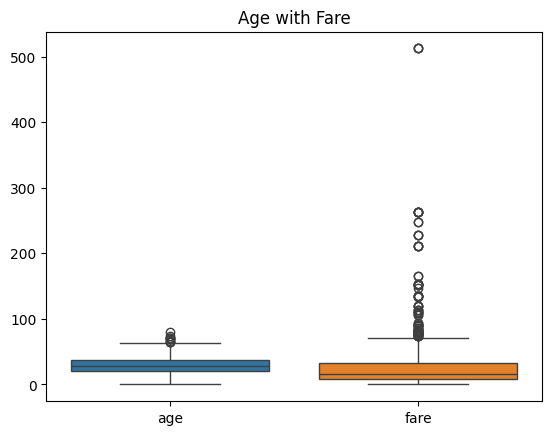

In [44]:
import seaborn as sns
import matplotlib.pyplot as plt

# sns.boxplot(x='Age', y='Salary', data=df)

sns.boxplot(df)
# plt.boxplot(x='Age', y='Salary', data=df) 
plt.title("Age with Fare")
plt.show()

## Identify Outliers Using Z-score

In [45]:
z_scores = np.abs(stats.zscore(df))
outliers_z= (z_scores >3)
outliers_z

array([[False, False],
       [False, False],
       [False, False],
       ...,
       [False, False],
       [False, False],
       [False, False]], shape=(714, 2))

## IQR method

In [46]:
Q1 = df.quantile(0.25)
Q3 = df.quantile(0.75)
IQR = Q3 - Q1
outlier_iqr = ((df < (Q1 - 1.5 * IQR)) | (df > (Q3 + 1.5 * IQR)))
outlier_iqr

,age,fare
0,False,False
1,False,False
2,False,False
3,False,False
4,False,False
...,...,...
885,False,False
886,False,False
887,False,False
889,False,False


## Remove outliers

In [47]:
df_no_outliers = df[~((df < (Q1 - 1.5 * IQR)) |(df > (Q3 + 1.5 * IQR))).any(axis=1)]
df_no_outliers

,age,fare
0,22.0,7.2500
1,38.0,71.2833
2,26.0,7.9250
3,35.0,53.1000
4,35.0,8.0500
...,...,...
885,39.0,29.1250
886,27.0,13.0000
887,19.0,30.0000
889,26.0,30.0000


## Replace Outliters with Median

In [48]:
df_replace_median= df.copy()
for col in df.columns:
    median = df[col].median()
    df_replace_median[col] = np.where(outlier_iqr[col], median, df[col])

df_replace_median

,age,fare
0,22.0,7.2500
1,38.0,71.2833
2,26.0,7.9250
3,35.0,53.1000
4,35.0,8.0500
...,...,...
885,39.0,29.1250
886,27.0,13.0000
887,19.0,30.0000
889,26.0,30.0000


## Cap Outliers (winsorization)

In [49]:
df_winsorized = df.copy()
for col in df.columns:
    lower_limit = Q1[col] - 1.5 * IQR[col]
    upper_limit = Q3[col] + 1.5 * IQR[col]
    df_winsorized[col] = np.where(df[col] < lower_limit, lower_limit, df[col])
    df_winsorized[col] = np.where(df_winsorized[col] > upper_limit, upper_limit, df_winsorized[col])

df_winsorized

,age,fare
0,22.0,7.2500
1,38.0,71.2833
2,26.0,7.9250
3,35.0,53.1000
4,35.0,8.0500
...,...,...
885,39.0,29.1250
886,27.0,13.0000
887,19.0,30.0000
889,26.0,30.0000


## Log Transformation (only for positive values)

In [50]:
df_log=df.copy()
df_log['Salary'] = np.log(df_log['fare'])
df_log

c:\Users\mdfah\anaconda3\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


,age,fare,Salary
0,22.0,7.2500,1.981001
1,38.0,71.2833,4.266662
2,26.0,7.9250,2.070022
3,35.0,53.1000,3.972177
4,35.0,8.0500,2.085672
...,...,...,...
885,39.0,29.1250,3.371597
886,27.0,13.0000,2.564949
887,19.0,30.0000,3.401197
889,26.0,30.0000,3.401197


## Robust Scaling
### s= (X - Median)/IQR

In [51]:
scaler= RobustScaler()
df_scaled= pd.DataFrame(scaler.fit_transform(df), columns=df.columns)
df_scaled

,age,fare
0,-0.335664,-0.335309
1,0.559441,2.193153
2,-0.111888,-0.308655
3,0.391608,1.475155
4,0.391608,-0.303720
...,...,...
709,0.615385,0.528462
710,-0.055944,-0.108261
711,-0.503497,0.563013
712,-0.111888,0.563013
